In [9]:
# import libraries 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Text(0.5, 0, 'X dataset')

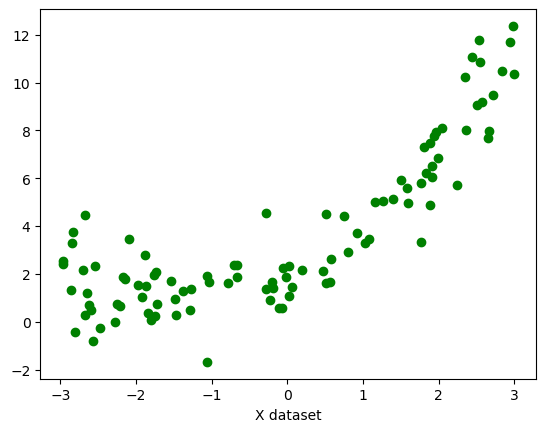

In [10]:
X = 6 * np.random.rand(100,1) - 3

y = 0.5 * X**2 + 1.5 * X + 2 + np.random.randn(100,1)

#quadratic equations used - y = 0.5 x^2 + 1.5x + 2 + outliers
plt.scatter(X ,y ,color = "g")

plt.xlabel("X dataset")

In [11]:
pip show notebook


Name: notebookNote: you may need to restart the kernel to use updated packages.

Version: 6.5.4
Summary: A web-based notebook environment for interactive computing
Home-page: http://jupyter.org
Author: Jupyter Development Team
Author-email: jupyter@googlegroups.com
License: BSD
Location: C:\Users\lenovo\anaconda3\Lib\site-packages
Requires: argon2-cffi, ipykernel, ipython-genutils, jinja2, jupyter-client, jupyter-core, nbclassic, nbconvert, nbformat, nest-asyncio, prometheus-client, pyzmq, Send2Trash, terminado, tornado, traitlets
Required-by: jupyter, jupyterlab, jupyterthemes


In [12]:
# this is not linear data set :

from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test =  train_test_split(X,y ,test_size =0.2 , 
                                                        random_state =42)


In [13]:
# lets implement simple linear regression 

from sklearn.linear_model import LinearRegression 
regression_1 = LinearRegression()

In [14]:
regression_1.fit(X_train , y_train)

LinearRegression()

In [15]:
from sklearn.metrics import r2_score

score = r2_score(y_test , regression_1.predict(X_test))

In [16]:
print(score)           # we are getting less accuraccy.

0.6981070125585268


Text(0, 0.5, 'y ')

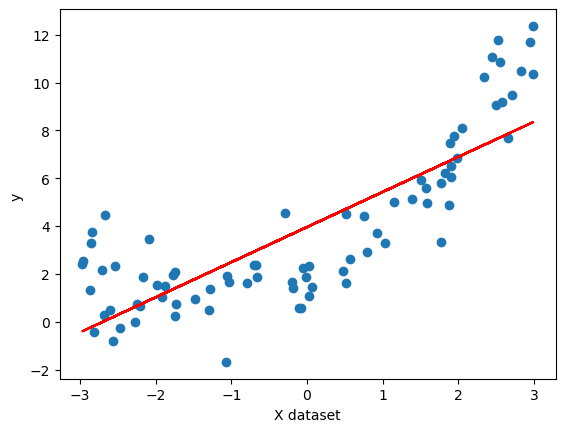

In [17]:
#  lets do visualization 

plt.plot(X_train , regression_1.predict(X_train) , color ="r")

plt.scatter(X_train ,y_train)
plt.xlabel("X dataset")
plt.ylabel("y ")

In [18]:
# is is showing error bcz we fit this from linear regression so lets see how to resolve it .


In [19]:
# lets apply polynomial transformation 
from sklearn.preprocessing import PolynomialFeatures

In [20]:
poly =  PolynomialFeatures( degree = 2 , include_bias =True)


In [21]:
X_train_poly  = poly.fit_transform(X_train)  # fit_transform : no reference of test data is taken .

X_test_poly = poly.transform(X_test)      # only transform

In [22]:
X_train_poly # her ewe have 3 column , first- 1 (bias) , second-  x1 (feature) , third -x1^2 (x1 square)

array([[ 1.00000000e+00,  4.73160592e-01,  2.23880946e-01],
       [ 1.00000000e+00,  1.82590613e+00,  3.33393318e+00],
       [ 1.00000000e+00,  1.02546504e+00,  1.05157855e+00],
       [ 1.00000000e+00, -1.74793356e+00,  3.05527173e+00],
       [ 1.00000000e+00, -2.47623297e+00,  6.13172974e+00],
       [ 1.00000000e+00, -2.56671470e+00,  6.58802434e+00],
       [ 1.00000000e+00,  1.57719178e+00,  2.48753391e+00],
       [ 1.00000000e+00,  6.54681520e-02,  4.28607893e-03],
       [ 1.00000000e+00, -7.03522945e-01,  4.94944534e-01],
       [ 1.00000000e+00, -1.99237382e-01,  3.96955343e-02],
       [ 1.00000000e+00, -2.96936993e+00,  8.81715780e+00],
       [ 1.00000000e+00,  2.34416325e+00,  5.49510134e+00],
       [ 1.00000000e+00, -2.27822718e+00,  5.19031909e+00],
       [ 1.00000000e+00,  1.58932477e+00,  2.52595323e+00],
       [ 1.00000000e+00, -7.87420666e-01,  6.20031305e-01],
       [ 1.00000000e+00,  2.83042242e+00,  8.01129109e+00],
       [ 1.00000000e+00, -2.81003793e+00

In [23]:
X_test_poly

array([[ 1.        ,  2.66746748,  7.11538274],
       [ 1.        , -1.38466493,  1.91729697],
       [ 1.        , -1.46644528,  2.15046175],
       [ 1.        , -0.23480047,  0.05513126],
       [ 1.        ,  1.07819785,  1.1625106 ],
       [ 1.        ,  1.80198022,  3.24713271],
       [ 1.        , -0.28005089,  0.0784285 ],
       [ 1.        , -2.62486417,  6.88991191],
       [ 1.        , -2.64467557,  6.99430885],
       [ 1.        , -1.54511104,  2.38736812],
       [ 1.        ,  1.26460512,  1.5992261 ],
       [ 1.        , -1.80222896,  3.24802922],
       [ 1.        ,  2.35574696,  5.54954373],
       [ 1.        , -1.87724773,  3.52405904],
       [ 1.        ,  0.18887375,  0.03567329],
       [ 1.        ,  0.56676802,  0.32122599],
       [ 1.        ,  2.24640693,  5.04634409],
       [ 1.        ,  1.96047418,  3.84345903],
       [ 1.        , -2.14738346,  4.61125571],
       [ 1.        , -1.84321983,  3.39745934]])

In [24]:
# try apply same linear regresison
from sklearn.metrics import r2_score

regression  = LinearRegression()

regression.fit(X_train_poly , y_train)

y_pred = regression.predict(X_test_poly)

score = r2_score(y_test, y_pred)

print(score)

0.8555226874511419


from 0.59 to 0.85 : score has increased

In [25]:
# graph

print(regression.coef_)      # thre coeficient

[[0.         1.52997414 0.54710319]]


In [26]:
print(regression.intercept_)    # onyl 1 

[1.96244583]


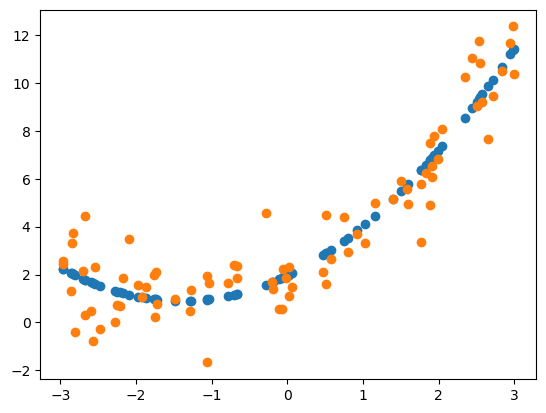

In [27]:
# lets take some new data and plot this 

plt.scatter(X_train , regression.predict(X_train_poly))
plt.scatter(X_train , y_train)

so this is how your best fit line occure

# if degree is 3 ? 

In [28]:
X_new = np.linspace(-3 ,3 ,200).reshape(200,1)
X_new_poly = poly.transform(X_new)

X_new_poly

array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00],
       [ 1.00000000e+00, -2.90954774e+00,  8.46546804e+00],
       [ 1.00000000e+00, -2.87939698e+00,  8.29092700e+00],
       [ 1.00000000e+00, -2.84924623e+00,  8.11820409e+00],
       [ 1.00000000e+00, -2.81909548e+00,  7.94729931e+00],
       [ 1.00000000e+00, -2.78894472e+00,  7.77821267e+00],
       [ 1.00000000e+00, -2.75879397e+00,  7.61094417e+00],
       [ 1.00000000e+00, -2.72864322e+00,  7.44549380e+00],
       [ 1.00000000e+00, -2.69849246e+00,  7.28186157e+00],
       [ 1.00000000e+00, -2.66834171e+00,  7.12004747e+00],
       [ 1.00000000e+00, -2.63819095e+00,  6.96005151e+00],
       [ 1.00000000e+00, -2.60804020e+00,  6.80187369e+00],
       [ 1.00000000e+00, -2.57788945e+00,  6.64551400e+00],
       [ 1.00000000e+00, -2.54773869e+00,  6.49097245e+00],
       [ 1.00000000e+00, -2.51758794e+00

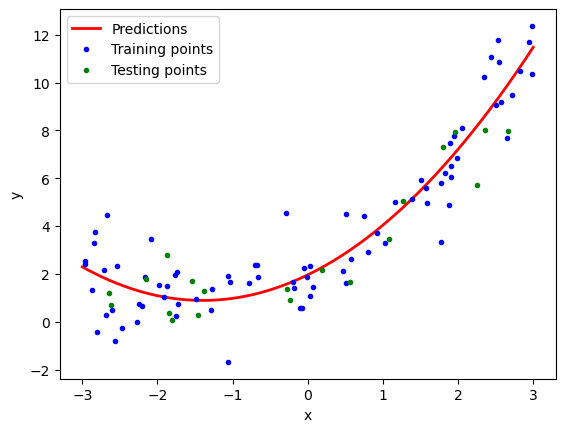

In [29]:
# use regression 
y_new  = regression.predict(X_new_poly)

plt.plot(X_new , y_new  , "r-" , linewidth = 2 , label = "Predictions")

plt.plot(X_train , y_train , "b." ,label = "Training points")

plt.plot(X_test , y_test , "g." , label = "Testing points")

plt.xlabel("x")

plt.ylabel("y")

plt.legend()
plt.show()

In [30]:
# we have implemented  same data with models with  different polynomial degree , and 
# best result is given by the model having degree 2 

# pipeline  concept

In [31]:
from sklearn.pipeline import Pipeline

In [32]:
def poly_regression(degree):
    
    X_new = np.linspace(-3 , 3,200).reshape(200 , 1)
    # The numpy.linspace function is used to create an array of evenly spaced values over a specified range.
    
    poly_features = PolynomialFeatures(degree = degree , include_bias = True )
    
    lin_reg = LinearRegression()
    
    poly_regression = Pipeline([
        ("poly_features",poly_features),
        ("lin_reg" , lin_reg)
    ])
    
    poly_regression.fit(X_train , y_train)
    
    y_pred_new  = poly_regression.predict(X_new)
    
    
    # plotting predicted the line
    
    plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)
    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-4,4, 0, 10])
    plt.show()
    

* poly_features = PolynomialFeatures(degree = degree , include_bias = True )

PolynomialFeatures object from scikit-learn with the specified degree. This object will be used to transform the original features into polynomial features.

python

* lin_reg = LinearRegression()

This creates a linear regression model (LinearRegression from scikit-learn) that will be used to fit the polynomial features.


    
* poly_regression = Pipeline([
        ("poly_features",poly_features),
        ("lin_reg" , lin_reg)
    ])
    
You create a scikit-learn Pipeline object that consists of two steps:

first, it applies the polynomial feature transformation (poly_features), and 

then it fits a linear regression model (lin_reg) to the transformed data.
    
* poly_regression.fit(X_train , y_train)

This line fits the polynomial regression model to the training data X_train and y_train, where X_train are the input features, and y_train are the target values
    
* y_pred_new  = poly_regression.predict(X_new)
You use the trained polynomial regression model to make predictions on the new input data X_new, resulting in predicted values stored in y_pred_new.

    
 #plotting predicted the line
    
* plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)

This line plots the predicted values y_pred_new against the new input data X_new as a red line, and it includes a label indicating the degree of the polynomial being used for this plot.


* plt.plot(X_train, y_train, "b.", linewidth=3)
  plt.plot(X_test, y_test, "g.", linewidth=3)

  These lines plot the original training data points (X_train and y_train) as blue dots and the test data points (X_test and y_test) as green dots.


    

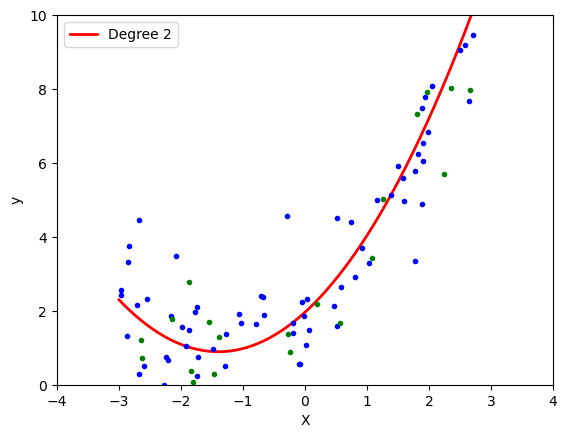

In [33]:
poly_regression(2)

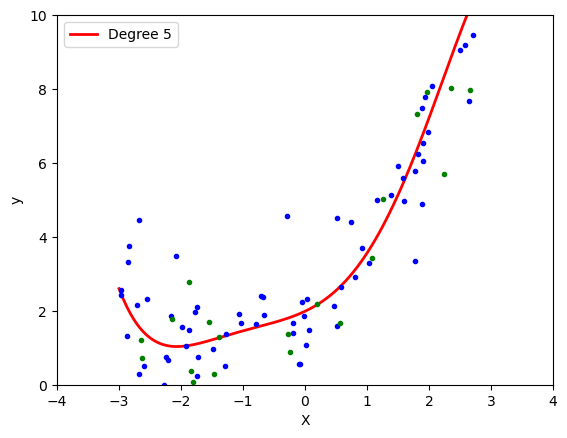

In [34]:
poly_regression(5)

In [35]:
# as we  increse degree model start overfitting each data point
